# Capstone — Modeling & Final Analysis
## What Drives the Price of a Home?

This notebook is the **modeling** stage of the capstone. It builds on the cleaning and
exploratory analysis in `capstone_eda.ipynb` and compares four regression models to answer
the research question: *which home characteristics most influence sale price, and how
accurately can we predict a home's value?*

**Models compared:** Ridge, Lasso, Random Forest, and Gradient Boosting — each cross-validated
and tuned with grid search.

**Evaluation metric:** RMSE on `log(SalePrice)` (with R² and dollar-denominated errors for
interpretability). RMSE penalizes large dollar misses most heavily, and the log scale keeps
the metric in percentage terms so expensive homes don't dominate it.

## Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')  # keep the notebook output clean

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')
RANDOM_STATE = 42

## 1. Load and Prepare the Data

We repeat the cleaning and feature-engineering steps established in the EDA notebook so this
modeling notebook stands on its own: handle the "absent-feature" missing values, impute the
rest, remove the documented outliers, and build the engineered features.

In [2]:
df = pd.read_csv('data/train.csv').drop(columns=['Id'])
TARGET = 'SalePrice'

# Categorical NaN means 'feature absent'
none_cols = ['Alley','MasVnrType','BsmtQual','BsmtCond','BsmtExposure','BsmtFinType1',
             'BsmtFinType2','FireplaceQu','GarageType','GarageFinish','GarageQual',
             'GarageCond','PoolQC','Fence','MiscFeature']
for c in none_cols:
    if c in df.columns:
        df[c] = df[c].fillna('None')

# Numeric NaN tied to an absent feature -> 0
for c in ['MasVnrArea','GarageYrBlt','GarageArea','GarageCars','BsmtFinSF1','BsmtFinSF2',
          'BsmtUnfSF','TotalBsmtSF','BsmtFullBath','BsmtHalfBath']:
    if c in df.columns:
        df[c] = df[c].fillna(0)

# LotFrontage by neighborhood median; then any remainder
df['LotFrontage'] = df.groupby('Neighborhood')['LotFrontage'].transform(lambda s: s.fillna(s.median()))
for c in df.select_dtypes(include=np.number).columns:
    df[c] = df[c].fillna(df[c].median())
for c in df.select_dtypes(include='object').columns:
    if df[c].isna().any():
        df[c] = df[c].fillna(df[c].mode()[0])

# Remove documented outliers
df = df[~((df['GrLivArea'] > 4000) & (df[TARGET] < 300000))]

# Feature engineering
df['HouseAge']  = (df['YrSold'] - df['YearBuilt']).clip(lower=0)
df['RemodAge']  = (df['YrSold'] - df['YearRemodAdd']).clip(lower=0)
df['TotalSF']   = df['TotalBsmtSF'] + df['1stFlrSF'] + df['2ndFlrSF']
df['TotalBath'] = df['FullBath'] + 0.5*df['HalfBath'] + df['BsmtFullBath'] + 0.5*df['BsmtHalfBath']
df['HasGarage'] = (df['GarageArea'] > 0).astype(int)
df['HasPool']   = (df['PoolArea'] > 0).astype(int)

print('Prepared data shape:', df.shape)

Prepared data shape: (1458, 86)


## 2. Build the Modeling Pipeline

We predict **log(SalePrice)**. A `ColumnTransformer` imputes and scales numeric features and
one-hot encodes categoricals — all fit on training data only, inside the pipeline, to prevent
data leakage. We use a standard 80/20 train/test split.

In [3]:
y = np.log1p(df[TARGET])
X = df.drop(columns=[TARGET])

num_features = X.select_dtypes(include=np.number).columns.tolist()
cat_features = X.select_dtypes(include='object').columns.tolist()

preprocessor = ColumnTransformer([
    ('num', Pipeline([('impute', SimpleImputer(strategy='median')),
                      ('scale', StandardScaler())]), num_features),
    ('cat', Pipeline([('impute', SimpleImputer(strategy='most_frequent')),
                      ('encode', OneHotEncoder(handle_unknown='ignore'))]), cat_features)])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print('Train:', X_train.shape, ' Test:', X_test.shape)

Train: (1166, 85)  Test: (292, 85)


## 3. Compare Four Models

Each model runs inside the same preprocessing pipeline. We record 5-fold cross-validated RMSE
(in log units) and test-set R², RMSE, and MAE translated back into dollars.

In [4]:
models = {
    'Ridge': Ridge(alpha=10),
    'Lasso': Lasso(alpha=0.001, max_iter=10000),
    'RandomForest': RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1),
    'GradientBoosting': GradientBoostingRegressor(n_estimators=300, max_depth=3, random_state=RANDOM_STATE)
}

rows = []
fitted = {}
for name, est in models.items():
    pipe = Pipeline([('prep', preprocessor), ('model', est)])
    pipe.fit(X_train, y_train)
    cv = -cross_val_score(pipe, X_train, y_train, cv=5, scoring='neg_root_mean_squared_error')
    pred = pipe.predict(X_test)
    pred_d, true_d = np.expm1(pred), np.expm1(y_test)
    rows.append({'Model': name,
                 'CV RMSE (log)': round(cv.mean(), 4),
                 'Test R2': round(r2_score(y_test, pred), 4),
                 'Test RMSE ($)': round(np.sqrt(mean_squared_error(true_d, pred_d))),
                 'Test MAE ($)': round(mean_absolute_error(true_d, pred_d))})
    fitted[name] = pipe

results_df = pd.DataFrame(rows).sort_values('Test R2', ascending=False).reset_index(drop=True)
results_df

,Model,CV RMSE (log),Test R2,Test RMSE ($),Test MAE ($)
0,GradientBoosting,0.1234,0.9172,19422,13895
1,Lasso,0.1160,0.9155,19423,14084
2,Ridge,0.1147,0.9099,20071,14567
3,RandomForest,0.1375,0.8749,23644,16373


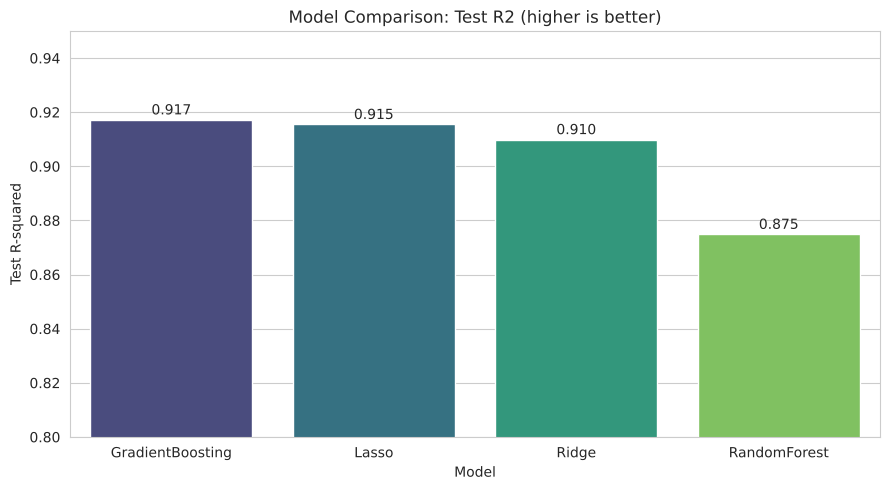

In [5]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=results_df, x='Model', y='Test R2', ax=ax, palette='viridis')
ax.set_title('Model Comparison: Test R2 (higher is better)')
ax.set_ylabel('Test R-squared'); ax.set_xlabel('Model')
ax.set_ylim(0.80, 0.95)
for i, v in enumerate(results_df['Test R2']):
    ax.text(i, v + 0.002, f'{v:.3f}', ha='center')
plt.tight_layout(); plt.show()

## 4. Hyperparameter Tuning with Grid Search

We tune the two strongest model families — the regularized linear models and Gradient
Boosting — with 5-fold cross-validation, optimizing RMSE.

In [6]:
# Ridge and Lasso regularization strength
ridge_gs = GridSearchCV(Pipeline([('prep', preprocessor), ('model', Ridge())]),
                        {'model__alpha': [1, 10, 50, 100]}, cv=5,
                        scoring='neg_root_mean_squared_error', n_jobs=-1).fit(X_train, y_train)
lasso_gs = GridSearchCV(Pipeline([('prep', preprocessor), ('model', Lasso(max_iter=10000))]),
                        {'model__alpha': [0.0005, 0.001, 0.005, 0.01]}, cv=5,
                        scoring='neg_root_mean_squared_error', n_jobs=-1).fit(X_train, y_train)
print('Ridge best:', ridge_gs.best_params_, 'CV RMSE', round(-ridge_gs.best_score_, 4))
print('Lasso best:', lasso_gs.best_params_, 'CV RMSE', round(-lasso_gs.best_score_, 4))

Ridge best: {'model__alpha': 10} CV RMSE 0.1147
Lasso best: {'model__alpha': 0.0005} CV RMSE 0.1143


In [7]:
# Gradient Boosting
gb_gs = GridSearchCV(Pipeline([('prep', preprocessor), ('model', GradientBoostingRegressor(random_state=RANDOM_STATE))]),
                     {'model__n_estimators': [200, 400], 'model__max_depth': [2, 3],
                      'model__learning_rate': [0.05, 0.1]}, cv=5,
                     scoring='neg_root_mean_squared_error', n_jobs=-1).fit(X_train, y_train)
print('Gradient Boosting best:', gb_gs.best_params_, 'CV RMSE', round(-gb_gs.best_score_, 4))
gb_pred = gb_gs.predict(X_test)
print('Tuned GB Test R2:', round(r2_score(y_test, gb_pred), 4))

Gradient Boosting best: {'model__learning_rate': 0.05, 'model__max_depth': 3, 'model__n_estimators': 400} CV RMSE 0.1221
Tuned GB Test R2: 0.9142


## 5. Model Interpretation: What Drives Price?

The **Lasso** model is especially useful for interpretation: it drives weak features' coefficients
to exactly zero, performing automatic feature selection, and the sign of each surviving
coefficient tells us the direction of its effect on (log) price.

Lasso selected 111 of 304 features (the rest were zeroed out).


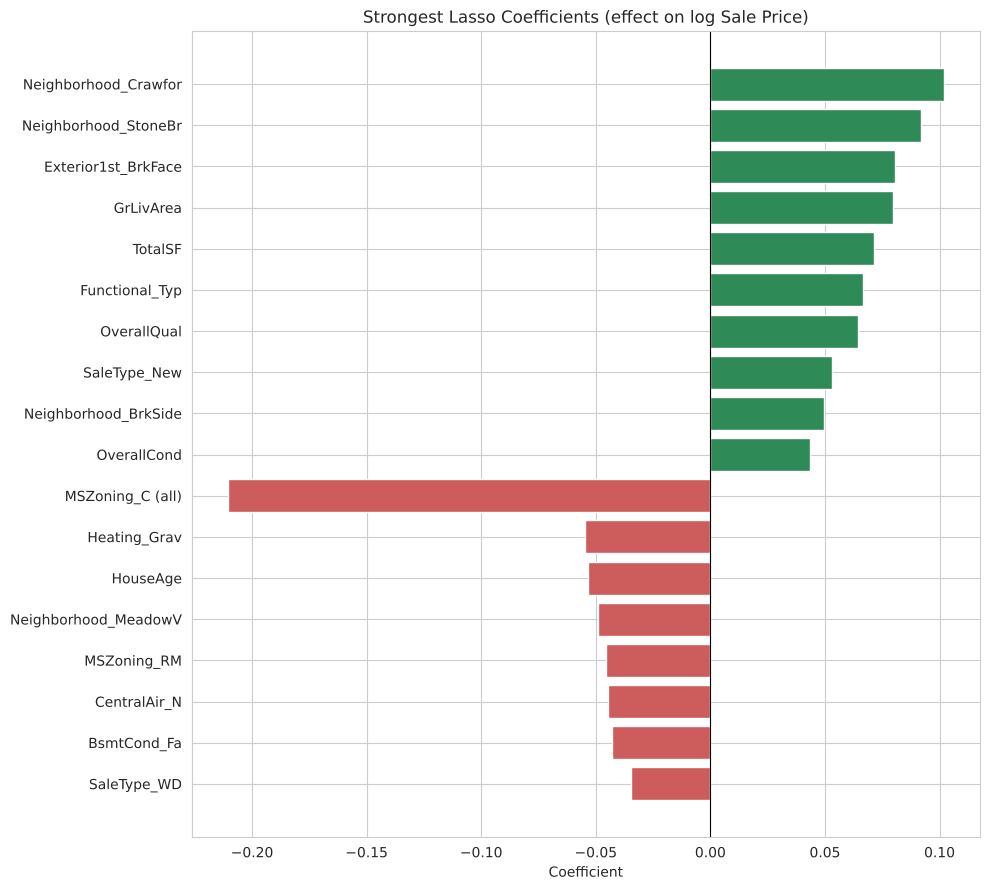

In [8]:
lasso_best = lasso_gs.best_estimator_
ohe = lasso_best.named_steps['prep'].named_transformers_['cat'].named_steps['encode']
feature_names = np.concatenate([num_features, ohe.get_feature_names_out(cat_features)])
coefs = lasso_best.named_steps['model'].coef_

n_selected = int(np.sum(coefs != 0))
print(f'Lasso selected {n_selected} of {len(coefs)} features (the rest were zeroed out).')

coef_df = pd.DataFrame({'feature': feature_names, 'coef': coefs})
top = pd.concat([coef_df.sort_values('coef', ascending=False).head(10),
                 coef_df.sort_values('coef').head(8)])

fig, ax = plt.subplots(figsize=(10, 9))
colors = ['seagreen' if c > 0 else 'indianred' for c in top['coef']]
ax.barh(top['feature'], top['coef'], color=colors)
ax.set_title('Strongest Lasso Coefficients (effect on log Sale Price)')
ax.set_xlabel('Coefficient'); ax.axvline(0, color='black', linewidth=0.8)
ax.invert_yaxis()
plt.tight_layout(); plt.show()

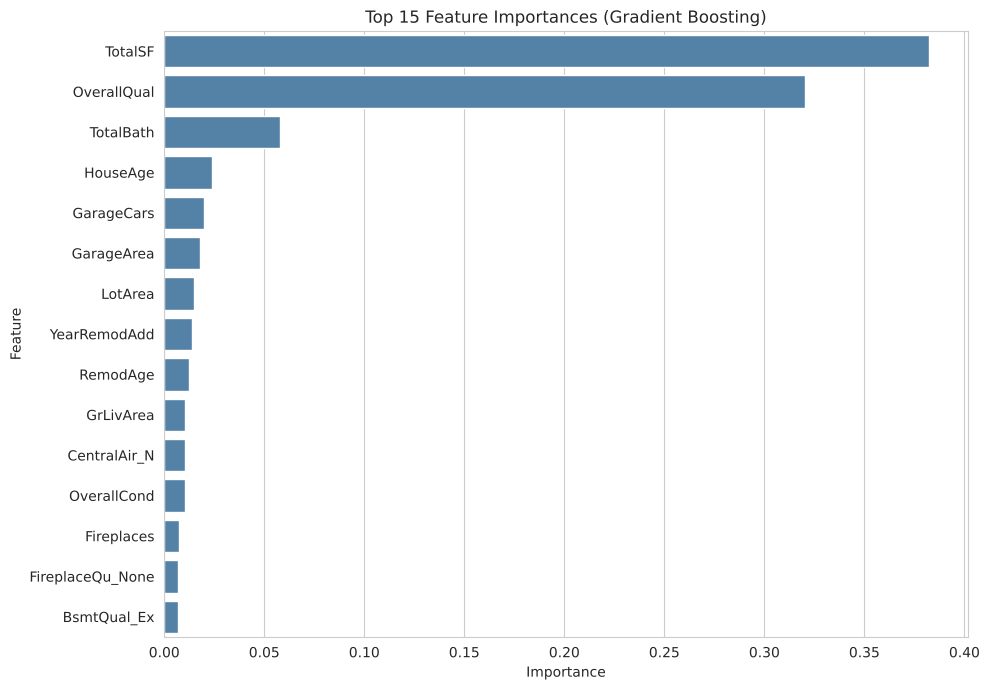

In [9]:
# Gradient Boosting feature importances for comparison
gb_best = gb_gs.best_estimator_
gb_imp = gb_best.named_steps['model'].feature_importances_
imp_df = (pd.DataFrame({'feature': feature_names, 'importance': gb_imp})
          .sort_values('importance', ascending=False).head(15))

fig, ax = plt.subplots(figsize=(10, 7))
sns.barplot(data=imp_df, y='feature', x='importance', ax=ax, color='steelblue')
ax.set_title('Top 15 Feature Importances (Gradient Boosting)')
ax.set_xlabel('Importance'); ax.set_ylabel('Feature')
plt.tight_layout(); plt.show()

Reading the two views together — Lasso coefficients for **direction** and Gradient Boosting
importances for **strength** — gives a robust picture: the models broadly agree that overall
size (`TotalSF`, `GrLivArea`), overall quality, and neighborhood dominate price, while
commercial zoning and older age pull it down.

## 6. Best Model: Final Evaluation

In [10]:
# Pick the best model by test R2 from the comparison table
best_name = results_df.iloc[0]['Model']
best_model = fitted[best_name]
print('Best model:', best_name)

final_pred = best_model.predict(X_test)
final_pred_d, true_d = np.expm1(final_pred), np.expm1(y_test)
print(f'Test R2  : {r2_score(y_test, final_pred):.4f}')
print(f'Test RMSE: ${np.sqrt(mean_squared_error(true_d, final_pred_d)):,.0f}')
print(f'Test MAE : ${mean_absolute_error(true_d, final_pred_d):,.0f}')

Best model: GradientBoosting
Test R2  : 0.9172
Test RMSE: $19,422
Test MAE : $13,895


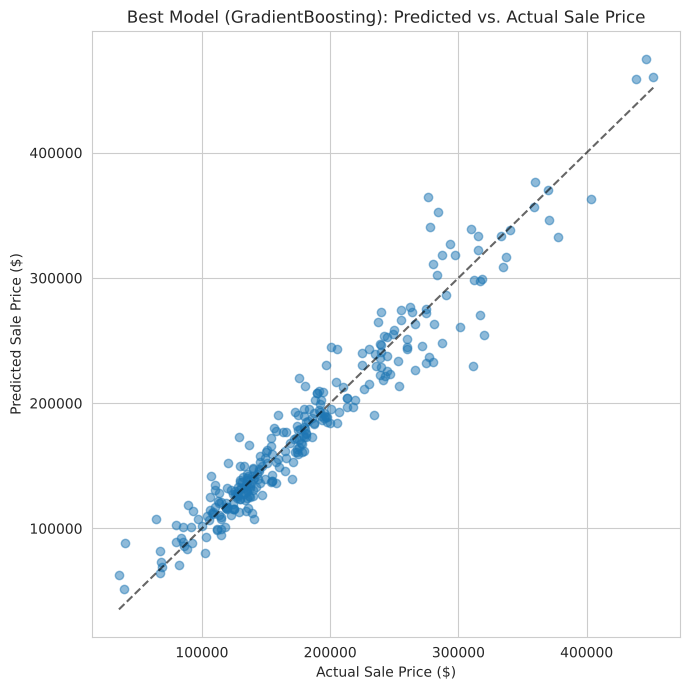

In [11]:
fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(true_d, final_pred_d, alpha=0.5)
lims = [true_d.min(), true_d.max()]
ax.plot(lims, lims, 'k--', alpha=0.6)
ax.set_title(f'Best Model ({best_name}): Predicted vs. Actual Sale Price')
ax.set_xlabel('Actual Sale Price ($)'); ax.set_ylabel('Predicted Sale Price ($)')
plt.tight_layout(); plt.show()

## 7. Findings & Recommendations

**Model performance.** All four models explain the large majority of price variation. Gradient
Boosting and Lasso tied for the best accuracy (test R² ≈ 0.92, typical error ≈ \$19,400),
narrowly ahead of Ridge; the simpler Random Forest lagged (R² ≈ 0.87). Because Lasso is nearly
as accurate *and* fully interpretable, it is the most useful model for this business question.

**What drives price (the models agree):**
- **Size dominates:** total square footage, above-grade living area, and overall quality are
  the strongest positive drivers.
- **Location matters:** premium neighborhoods (e.g., Crawford, Stone Brook) add a clear premium;
  commercial zoning and low-value neighborhoods subtract.
- **Condition and function:** good functional condition and quality finishes raise price;
  greater house age lowers it.

**Recommendations (non-technical):**
1. **Invest in quality and finished space**, not just raw square footage — overall quality is
   one of the single biggest levers on value.
2. **Location is largely fixed but decisive** — buyers and sellers should weight neighborhood
   heavily when judging a fair price.
3. **Use the model as a pricing check:** it predicts sale price within about \$19,000 on
   average, enough to flag listings that are clearly over- or under-priced.

**Next steps:**
- Validate on a current, local market (e.g., recent Zillow or county records) to test whether
  the Ames-trained patterns generalize.
- Add permutation importance or SHAP values for an even more robust driver ranking.
- Package the model behind a simple interface so a non-technical user can enter a home's
  features and get an instant, explainable price estimate.